# 00 · endf docs smoke test
Re-runs every example from the *ENDF Python Interface* docs (release 0.1.1, P. Romano) against our
container and data, to verify the shared environment.

- ENDF examples use **ENDF/B-VIII.1** `n-092_U_235.endf` (`scripts/download_endf.sh`).
  The docs were written against an older U-235 evaluation, so exact numbers may differ.
- ACE examples use `80198.710nc` from LANL ENDF71x (`scripts/download_ace_sample.sh`).

Each section ends with `assert`s so `jupyter nbconvert --execute` fails loudly if something breaks.

In [1]:
import os
from pathlib import Path
import numpy
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import endf

DATA = Path(os.environ.get("HEISENBIG_DATA", "../data"))
U235_PATH = DATA / "raw/endf-b8.1/neutrons/n-092_U_235.endf"
ACE_PATH = DATA / "raw/ace/80198.710nc"
from importlib.metadata import version
print("endf", version("endf"), "| numpy", numpy.__version__)
print(U235_PATH, U235_PATH.exists()); print(ACE_PATH, ACE_PATH.exists())

endf 0.1.12 | numpy 2.5.5
/workspace/data/raw/endf-b8.1/neutrons/n-092_U_235.endf True
/workspace/data/raw/ace/80198.710nc True


## 1.2.1 Low-level interface — `Material`

In [2]:
mat = endf.Material(U235_PATH)
print("MAT =", mat.MAT, "| #sections =", len(mat.sections))
assert mat.MAT == 9228

/usr/local/lib/python3.12/site-packages/endf/material.py:228: UserWarning: MF=31, MT=452 ignored
  warn(f"{MF=}, {MT=} ignored")
/usr/local/lib/python3.12/site-packages/endf/material.py:228: UserWarning: MF=31, MT=455 ignored
  warn(f"{MF=}, {MT=} ignored")
/usr/local/lib/python3.12/site-packages/endf/material.py:228: UserWarning: MF=31, MT=456 ignored
  warn(f"{MF=}, {MT=} ignored")


MAT = 9228 | #sections = 480


/usr/local/lib/python3.12/site-packages/endf/material.py:228: UserWarning: MF=35, MT=18 ignored
  warn(f"{MF=}, {MT=} ignored")


In [3]:
print(mat.section_text[12, 75])

 9.223500+4 2.330248+2          2          2         25          0922812 75
 4.386000+5 0.000000+0          0          0          3          1922812 75
 0.000000+0 1.000000+0 1.000000+0                                 922812 75



In [4]:
mat.section_data[3, 16]

{'ZA': 92235,
 'AWR': 233.0248,
 'QM': -5298000.0,
 'QI': -5298000.0,
 'LR': 0,
 'sigma': <Tabulated1D: 39 points, 1 regions>}

In [5]:
d = mat.section_data[3, 16]
assert d["ZA"] == 92235 and isinstance(d["sigma"], endf.Tabulated1D)

### Tabulated1D objects

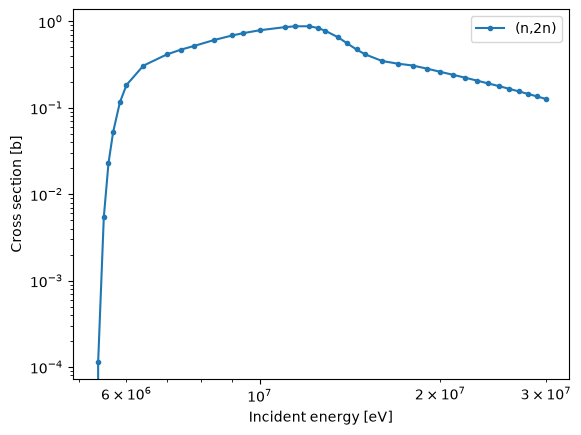

In [6]:
xs = mat.section_data[3, 16]['sigma']
plt.loglog(xs.x, xs.y, marker='.', label='(n,2n)')
plt.xlabel("Incident energy [eV]"); plt.ylabel("Cross section [b]"); plt.legend()
plt.show()

In [7]:
xs(9.5e6)

np.float64(0.7428240476190476)

In [8]:
energies = numpy.linspace(6.0e6, 8.0e6, 10)
xs(energies)

array([0.183841  , 0.25245628, 0.3152985 , 0.3550485 , 0.3947985 ,
       0.43081767, 0.463106  , 0.49255778, 0.52108125, 0.55290937])

In [9]:
vals = xs(energies)
assert isinstance(vals, np.ndarray) and vals.shape == (10,)
assert np.all(np.diff(vals) > 0)  # (n,2n) rises above threshold in 6-8 MeV
assert 0 < xs(9.5e6) < 3

## 1.2.2 High-level interface — `IncidentNeutron`

In [10]:
mat = endf.Material(U235_PATH)
u235 = mat.interpret()

In [11]:
u235 = endf.IncidentNeutron.from_endf(U235_PATH)
u235

<IncidentNeutron: U235, 95 reactions>

In [12]:
u235.reactions

{1: <Reaction: MT=1 (n,total)>,
 2: <Reaction: MT=2 (n,elastic)>,
 4: <Reaction: MT=4 (n,level)>,
 5: <Reaction: MT=5 (n,misc)>,
 16: <Reaction: MT=16 (n,2n)>,
 17: <Reaction: MT=17 (n,3n)>,
 18: <Reaction: MT=18 (n,fission)>,
 51: <Reaction: MT=51 (n,n1)>,
 52: <Reaction: MT=52 (n,n2)>,
 53: <Reaction: MT=53 (n,n3)>,
 54: <Reaction: MT=54 (n,n4)>,
 55: <Reaction: MT=55 (n,n5)>,
 56: <Reaction: MT=56 (n,n6)>,
 57: <Reaction: MT=57 (n,n7)>,
 58: <Reaction: MT=58 (n,n8)>,
 59: <Reaction: MT=59 (n,n9)>,
 60: <Reaction: MT=60 (n,n10)>,
 61: <Reaction: MT=61 (n,n11)>,
 62: <Reaction: MT=62 (n,n12)>,
 63: <Reaction: MT=63 (n,n13)>,
 64: <Reaction: MT=64 (n,n14)>,
 65: <Reaction: MT=65 (n,n15)>,
 66: <Reaction: MT=66 (n,n16)>,
 67: <Reaction: MT=67 (n,n17)>,
 68: <Reaction: MT=68 (n,n18)>,
 69: <Reaction: MT=69 (n,n19)>,
 70: <Reaction: MT=70 (n,n20)>,
 71: <Reaction: MT=71 (n,n21)>,
 72: <Reaction: MT=72 (n,n22)>,
 73: <Reaction: MT=73 (n,n23)>,
 74: <Reaction: MT=74 (n,n24)>,
 75: <Reaction

In [13]:
u235.reactions[16]

<Reaction: MT=16 (n,2n)>

In [14]:
u235[16]

<Reaction: MT=16 (n,2n)>

In [15]:
u235['n,2n']

<Reaction: MT=16 (n,2n)>

In [16]:
n2n = u235['n,2n']
n2n.xs

{'0K': <Tabulated1D: 39 points, 1 regions>}

In [17]:
n2n.products

[<Product: neutron, emission=prompt, yield=2.0>,
 <Product: U234, emission=prompt, yield=1.0>,
 <Product: photon, emission=prompt, yield=tabulated>]

In [18]:
photon = n2n.products[-1]
photon.yield_

<Tabulated1D: 38 points, 1 regions>

In [19]:
assert u235[16] is u235['n,2n'] is u235.reactions[16]
assert '0K' in n2n.xs
names = [p.name for p in n2n.products]
assert 'neutron' in names
print(names, n2n.q_reaction, n2n.q_massdiff)

['neutron', 'U234', 'photon'] -5298000.0 -5298000.0


## 1.2.3 ACE files

In [20]:
table = endf.ace.get_table(ACE_PATH)
table

<ACE Table: 80198.710nc at 293.6 K>

In [21]:
table.nxs

array([     0, 172118,  80198,   3180,     34,     25,     97,      4,
            0,      0,     80,    198,      0,      0,      0,      0,
            0])

In [22]:
assert table.nxs[0] == 0 and table.zaid == 80198
print("temperature [K]:", table.temperature, "| type:", table.data_type)

temperature [K]: 293.6059129982851 | type: TableType.NEUTRON_CONTINUOUS


In [23]:
hg198 = table.interpret()
hg198

<IncidentNeutron: Hg198, 38 reactions>

In [24]:
print(list(hg198[102].xs))
assert hg198.atomic_symbol == 'Hg' and hg198.mass_number == 198

['294K']


## API reference spot checks (chapter 2)

In [25]:
# Tabulated1D docstring example
f = endf.Tabulated1D([0, 10], [4, 5])
out = [f(xi) for xi in numpy.linspace(0, 10, 5)]
print(out); assert out == [4.0, 4.25, 4.5, 4.75, 5.0]
print("integral:", f.integral())
assert np.isclose(f.integral()[-1], 45.0)

[np.int64(4), np.float64(4.25), np.float64(4.5), np.float64(4.75), np.int64(5)]
integral: [ 0. 45.]


In [26]:
mats = endf.get_materials(U235_PATH)
assert len(mats) == 1 and mats[0].MAT == 9228
print(endf.ace.TableType.from_suffix('c'))
tables = endf.ace.get_tables(ACE_PATH)
print(tables)

TableType.NEUTRON_CONTINUOUS
[<ACE Table: 80198.710nc at 293.6 K>]


## Bonus: why ENDF MF=3 is *not* the dense data we need
In the resolved resonance region, MF=3 only holds a background; resonances live in MF=2 parameters.
Compare point counts for U-235 capture (MT=102) from ENDF vs. a reconstructed ACE table (Hg-198).

U-235 ENDF MF3 MT102 points: 111
Hg-198 ACE MT102 points (reconstructed+broadened): 3180


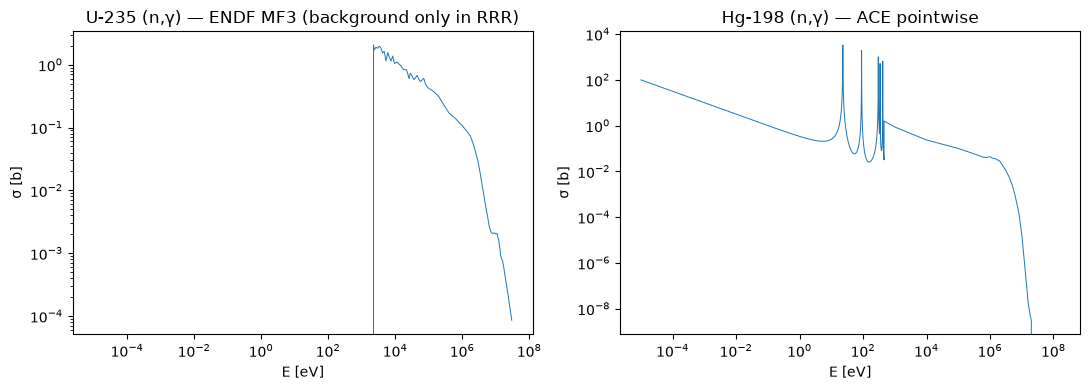

In [27]:
cap = u235[102].xs['0K']
print("U-235 ENDF MF3 MT102 points:", cap.n_pairs)
ace_cap = hg198[102].xs[next(iter(hg198[102].xs))]
print("Hg-198 ACE MT102 points (reconstructed+broadened):", len(ace_cap.x))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(cap.x, cap.y, lw=.7); ax[0].set_title("U-235 (n,γ) — ENDF MF3 (background only in RRR)")
ax[1].loglog(ace_cap.x, ace_cap.y, lw=.7); ax[1].set_title("Hg-198 (n,γ) — ACE pointwise")
for a in ax: a.set_xlabel("E [eV]"); a.set_ylabel("σ [b]")
plt.tight_layout(); plt.show()